In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import os.path as op

root_dir = '/raid1/mmenessini/calibration/ekarus'

In [14]:
def get_rec(rMod,nSubap,nModes):
    return fits.getdata(op.join(root_dir,'rec',f'pyr{rMod:1.1f}_{nSubap:.0f}x{nSubap:.0f}_{nModes:.0f}modes.fits'))

def get_og(rMod,nSubap,seeing):
    return fits.getdata(op.join(root_dir,'optgains',f'pyr{rMod:1.1f}_{nSubap:.0f}x{nSubap:.0f}_s{seeing:.1f}_og_pl.fits'))

(3000, 120, 120) (3000, 5396)


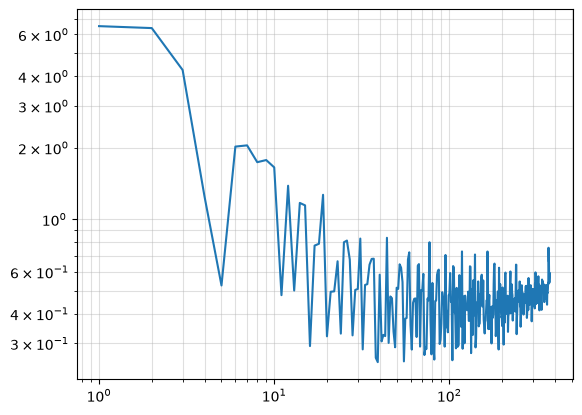

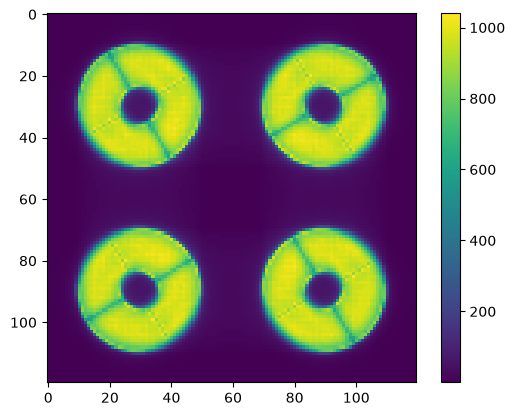

In [7]:
frames = fits.getdata(op.join(root_dir,'scratch_aliasing','frames.fits'))
signals = fits.getdata(op.join(root_dir,'scratch_aliasing','pyr_signals.fits'))
print(frames.shape,signals.shape)

rec = get_rec(rMod=3,nModes=375,nSubap=40)
modes = (rec @ signals.T).T

plt.figure()
plt.loglog(np.arange(rec.shape[0])+1,np.std(modes,axis=0))
plt.grid(which='both',alpha=0.4)

plt.figure()
plt.imshow(np.mean(frames,axis=0))
plt.colorbar()

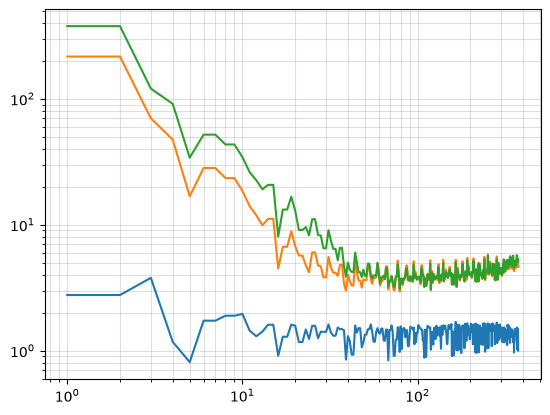

In [5]:
rec0 = get_rec(rMod=0,nModes=375,nSubap=40)
rec4 = get_rec(rMod=4,nModes=375,nSubap=40)
rec3 = get_rec(rMod=3,nModes=375,nSubap=40)

plt.figure()
plt.loglog(np.arange(rec0.shape[0])+1,np.diag(rec0 @ rec0.T))
plt.loglog(np.arange(rec3.shape[0])+1,np.diag(rec3 @ rec3.T))
plt.loglog(np.arange(rec4.shape[0])+1,np.diag(rec4 @ rec4.T))
plt.grid(which='both',alpha=0.4)

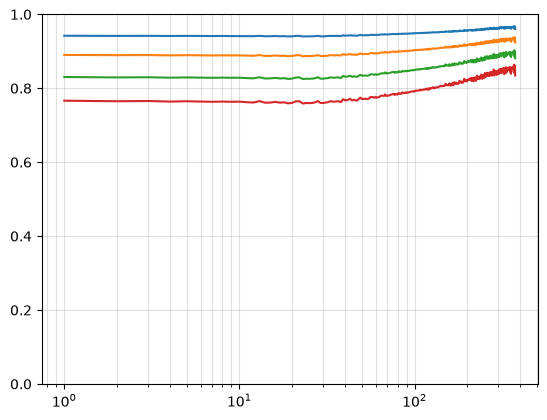

In [17]:
og0s10 = get_og(rMod=3,nSubap=40,seeing=1.0)
og0s15 = get_og(rMod=3,nSubap=40,seeing=1.5)
og0s20 = get_og(rMod=3,nSubap=40,seeing=2.0)
og0s25 = get_og(rMod=3,nSubap=40,seeing=2.5)

plt.figure()
plt.loglog(np.arange(len(og0s10))+1,og0s10)
plt.loglog(np.arange(len(og0s15))+1,og0s15)
plt.loglog(np.arange(len(og0s20))+1,og0s20)
plt.loglog(np.arange(len(og0s25))+1,og0s25)
plt.yscale('linear')
plt.ylim([0,1])
plt.grid(which='both',alpha=0.4)